In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [127]:
def ssa_hyperbolic(y0,x0,tau):
    y=y0               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=y[0]
    for i in np.arange(2,len(y)):
        y_tot1+=i*y[i]
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    while t_y<tau:
        dummy = y1[0]                                               
        y1[0] = 1
        c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state
        y1[0] = dummy
        N1 = len(c_idx1)  #number of non-zero species
        num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)              #possible number of reactions given the system state 
        a1 = np.zeros(num_reax1)                                     #reaction hazards 
        v1 = np.zeros([num_reax1,max_size]) 
        
        
        a1[0]=(k_tr*y_tot1)/(1+K*(y_tot1+y_tot2)/(s0*n))**n
        v1[0,0] = 1
        a1[1] = 0.5*beta*y1[0]*(y1[0]-1)
        v1[1,0] = -2
        v1[1,2] = 1

        if N1>1:
            species_idx1 =np.zeros([2,num_reax1])
            count=1
            for i in np.arange(1,N1):   #plasmid recruitment
                count+=1
                a1[count] = beta*y1[0]*y1[c_idx1[i]]
                species_idx1[:,count] = np.array([c_idx1[i],0])
            rec_count=count
                
            for i in np.arange(1,N1):   #cluster combination
                for j in np.arange(i,N1):
                    count+=1
                    if i==j:
                        a1[count] = 0.5*gamma*y1[c_idx1[i]]*(y1[c_idx1[j]]-1)
                    else:
                        a1[count] = gamma*y1[c_idx1[i]]*y1[c_idx1[j]]
                    species_idx1[:,count] = [c_idx1[i],c_idx1[j]]
            cluster_count = count
            
            for i in np.arange(1,N1): #plasmid shedding
                count+=1
                a1[count] = sigma*y1[c_idx1[i]]*c_idx1[i]
                species_idx1[:,count] = np.array([c_idx1[i],0])
                    
            for i in range(len(a1)): #reaction vectors
                if i==0:                         #plasmid replication
                    v1[i,0] = 1
                elif i==1:                       #plasmid duplex formation
                    v1[i,0] = -2
                    v1[i,2] = 1
                elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                    v1[i,0] = -1
                    v1[i,int(species_idx1[0,i])] = -1
                    v1[i,int(species_idx1[0,i])+1] = 1
                elif (i>rec_count and i<=cluster_count):   #cluster combination
                    if (int(species_idx1[0,i])==int(species_idx1[1,i])):
                        v1[i,int(species_idx1[0,i])] = -2
                    else:
                        v1[i,int(species_idx1[0,i])] = -1
                        v1[i,int(species_idx1[1,i])] = -1
                    v1[i,int(np.sum(species_idx1[:,i]))] = 1
                else:                            #plasmid shedding         
                    v1[i,0] = 1
                    v1[i,int(species_idx1[0,i])] = -1
                    v1[i,int(species_idx1[0,i])-1] = 1   
        
        ############################### pole 2 ##################################
        
        dummy = y2[0]
        y2[0]=1
        c_idx2 = np.where(y2>0)[0]                                  #indices of species with non-zero state
        y2[0]=dummy
        N2 = len(c_idx2)
        num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)              #possible number of reactions given the system state 
        a2 = np.zeros(num_reax2)                                     #reaction hazards 
        v2 = np.zeros([num_reax2,max_size]) 

        a2[0]=(k_tr*y_tot2)/(1+K*(y_tot1+y_tot2)/(s0*n))**n
        v2[0,0] = 1
        a2[1] = 0.5*beta*y2[0]*(y2[0]-1)
        v2[1,0] = -2
        v2[1,2] = 1    
        
        if N2>1:
            species_idx2 =np.zeros([2,num_reax2])
            count=1
            for i in np.arange(1,N2):   #plasmid recruitment
                count+=1
                a2[count] = beta*y2[0]*y2[c_idx2[i]]
                species_idx2[:,count] = np.array([c_idx2[i],0])
            rec_count=count
                
            for i in np.arange(1,N2):   #cluster combination
                for j in np.arange(i,N2):
                    count+=1
                    if i==j:
                        a2[count] = 0.5*gamma*y2[c_idx2[i]]*(y2[c_idx2[j]]-1)
                    else:
                        a2[count] = gamma*y2[c_idx2[i]]*y2[c_idx2[j]]
                    species_idx2[:,count] = [c_idx2[i],c_idx2[j]]
            cluster_count = count
            
            for i in np.arange(1,N2): #plasmid shedding
                count+=1
                a2[count] = sigma*y2[c_idx2[i]]*c_idx2[i]
                species_idx2[:,count] = np.array([c_idx2[i],0])
                    
            for i in range(len(a2)): #reaction vectors
                if i==0:                         #plasmid replication
                    v2[i,0] = 1
                elif i==1:                       #plasmid duplex formation
                    v2[i,0] = -2
                    v2[i,2] = 1
                elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                    v2[i,0] = -1
                    v2[i,int(species_idx2[0,i])] = -1
                    v2[i,int(species_idx2[0,i])+1] = 1
                elif (i>rec_count and i<=cluster_count):   #cluster combination
                    if (int(species_idx2[0,i])==int(species_idx2[1,i])):
                        v2[i,int(species_idx2[0,i])] = -2
                    else:
                        v2[i,int(species_idx2[0,i])] = -1
                        v2[i,int(species_idx2[1,i])] = -1
                    v2[i,int(np.sum(species_idx2[:,i]))] = 1
                else:                            #plasmid shedding         
                    v2[i,0] = 1
                    v2[i,int(species_idx2[0,i])] = -1
                    v2[i,int(species_idx2[0,i])-1] = 1   
        
        a = np.append(a1,a2,axis=0)
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        sum_a=np.sum(a)
        cumsum_a=np.cumsum(a,axis=0)
        epsilon=np.random.uniform(0,1,2)
        j=np.min(np.where(epsilon[0]*sum_a<cumsum_a)) 
        t_f=(np.log(1/epsilon[1]))/sum_a
                     
        if t_y+t_f<=tau:  
            t_y+=t_f 
            if (j==num_reax1+num_reax2):
                y2[0]+=1
                y1[0]-=1
            elif (j==num_reax1+num_reax2+1):
                y2[0]-=1
                y1[0]+=1
            elif (num_reax1<=j and j<num_reax1+num_reax2):
                y2+=v2[j%num_reax1,:]  
            else:
                y1+=v1[j,:]    

            y1[0]+=y1[1]
            y1[1]=0
            y2[0]+=y2[1]
            y2[1]=0
            
            y_tot1 =y1[0]
            y_tot2 =y2[0]
            for i in np.arange(1,max_size):
                y_tot1 +=i*y1[i] 
                y_tot2 +=i*y2[i]     
            y_tot = y_tot1+y_tot2
            
            if j==0:
                x= np.append(x,y_tot)
                t_x =np.append(t_x,[t_y])
        else:
            t_y=tau
            x=np.append(x,x[-1])
            t_x =np.append(t_x,[t_y])   
    y = np.append(y1,y2,axis=0)
    return y,x,t_y,t_x

def single_lineage(x0,gen,tau,cluster,thresh):
    x=[x0]
    t=[0]
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    cluster_num = np.zeros(gen)
    ratio = np.zeros([gen,2])  #ratio = [inheritance,parent]
    count=0
    for i in range(gen):
        if x0>0:
            count+=1
            yy,xx,tty,ttx=ssa_hyperbolic(y0,x0,tau)
            y0 = np.zeros(2*max_size)
            if cluster==False:
                x0=np.random.binomial(xx[-1],0.5)
                y0[0]=x0
            else:
                x=np.append(x,xx)
                t=np.append(t,t[-1]+ttx)
                pole = np.random.uniform(0,1)
                if pole<0.5:
                    y0[:max_size]=yy[:max_size]
                else:
                    y0[:max_size]=yy[max_size:]
                x0=0
                y0[1]=y0[0]
                for k in np.arange(1,len(y0)):
                    x0+=k*y0[k]
                y0[1]=0
            ratio[i,:]=[xx[-1],x0/xx[-1]]
        cluster_num[i] = np.sum(yy[thresh:max_size])+np.sum(yy[max_size+thresh:]) 
        #print('divide')
    return x,t,ratio[:count,:],cluster_num[:count]


def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[0,0].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[0,0].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[0,0].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[0,0].set_ylim([0,max(x)+1])
    axes[0,0].set_xlim([0,gen*tau])
    axes[0,0].set_xlabel('Time (min)')
    axes[0,0].set_ylabel('Plasmid copy number')
    return None

def plot_stairs_multiple(x,t,k):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[k].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[k].set_ylim([0,100])
    axes[k].set_xlim([0,gen*tau])
    axes[k].set_xlabel('time')
    axes[k].hlines(41,0,gen*tau,color='grey')
    if k>0:
        axes[k].set_yticklabels([])
    return None

In [131]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=500
beta = 0.006 #plasmid recruitment rate constant
gamma = 0.0045 #plasmid combination rate constant
sigma=0.005  #plasmid dissociation rate constant
rho = 0.01  #plasmid transfer rate constant

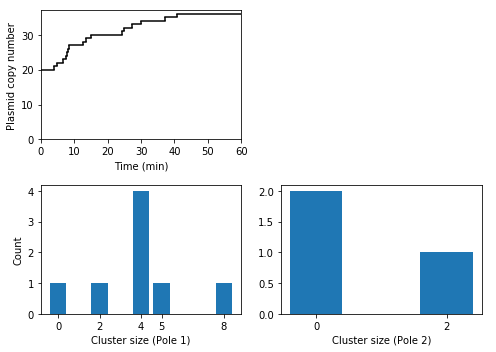

In [132]:
gen=1
y0 = np.zeros(2*max_size)
y0[0]=x0
f,axes = plt.subplots(2,2,figsize=(7,5))
y,x,t_y,t_x = ssa_hyperbolic(y0,x0,tau)
plot_stairs(x,t_x)
y1 = y[:max_size]
y2 = y[max_size:]
axes[0,1].axis('off')
axes[1,0].bar(range(np.max(np.where(y1>0))+1),y1[:np.max(np.where(y1>0))+1])
axes[1,0].set_xticks(np.where(y1>0)[0])
axes[1,1].bar(range(np.max(np.where(y2>0))+1),y2[:np.max(np.where(y2>0))+1])
axes[1,1].set_xticks(np.where(y2>0)[0])
for i in range(2):
    axes[1,i].set_xlabel('Cluster size (Pole %d)' %(i+1) )
axes[1,0].set_ylabel('Count')
plt.tight_layout()
plt.show()

What is a cluster? What is the threshold size for a group to be called a cluster?
We can keep track of the distribution of number of clusters in a lineage.



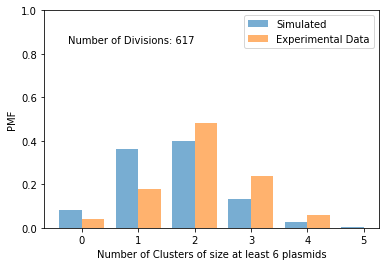

In [130]:
c_thresh = 6
cluster = True
gen=1000
x,t,ratio,c_num=single_lineage(x0,gen,tau,cluster,c_thresh)
heights = np.bincount(c_num.astype(int))/len(c_num)
bars = plt.bar(np.arange(len(heights))-0.2,heights,width=0.4,color='C0',alpha=0.6,label='Simulated') 
plt.text(-0.25,0.85,'Number of Divisions: %d' %len(c_num))
plt.bar(np.arange(5)+0.2,[0.04,0.18,0.48,0.24,0.06],width=0.4,color='C1',alpha=0.6,label='Experimental Data')
plt.ylim([0,1])
plt.xticks(range(len(heights)))
plt.xlabel('Number of Clusters of size at least %d plasmids' %(c_thresh))
plt.ylabel('PMF')
plt.legend()
plt.show()

<Figure size 432x288 with 0 Axes>

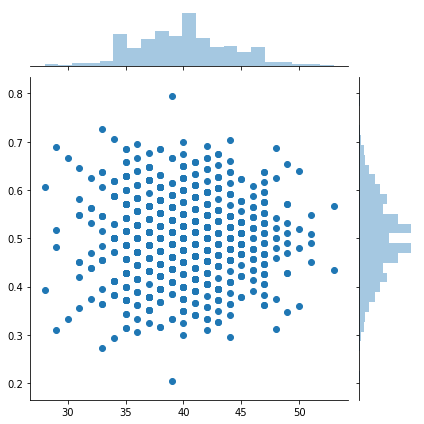

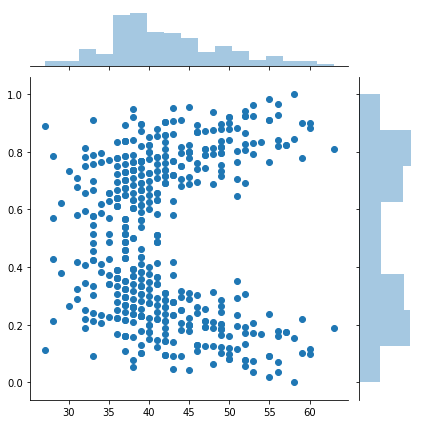

In [128]:
cluster=[False,True]
gen=500

f = plt.figure()
for j in range(2):
    x,t,ratio1,_=single_lineage(x0,gen,tau,cluster[j],0)
    ratio2 = np.zeros([len(ratio1),2])
    for i in range(len(ratio1)):
        ratio2[i,:]=[ratio1[i,0],1-ratio1[i,1]] 
    ratio = np.append(ratio1,ratio2,axis=0)
    sns.jointplot(ratio[:,0],ratio[:,1])
    if cluster[j]==True:
        ratio_c = ratio
    else:
        ratio_uc = ratio

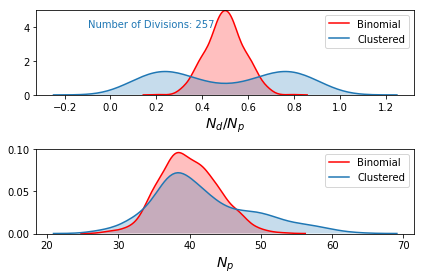

In [129]:
f,axes=plt.subplots(2,1)
sns.kdeplot(ratio_uc[:,1],label='Binomial',shade=True,ax=axes[0],color='r')
sns.kdeplot(ratio_c[:,1],label='Clustered',shade=True,ax=axes[0],color='C0')
axes[0].set_xlabel(r'$N_d/N_p$',fontsize=14)
axes[0].text(-0.1,4,'Number of Divisions: %d' %(int(len(ratio_c)/2)), color='C0')
axes[0].set_ylim([0,5])

sns.kdeplot(ratio_uc[:,0],label='Binomial',shade=True,ax=axes[1],color='r')
sns.kdeplot(ratio_c[:,0],label='Clustered',shade=True,ax=axes[1],color='C0')
axes[1].set_xlabel(r'$N_p$',fontsize=14)
plt.tight_layout()

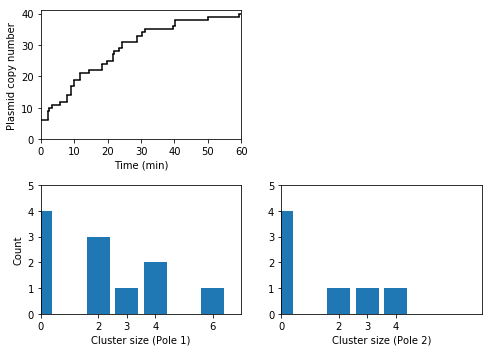

In [143]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=500
beta = 0.006 #plasmid recruitment rate constant
gamma = 0.0045 #plasmid combination rate constant
sigma=0.005  #plasmid dissociation rate constant
rho = 0.07  #plasmid transfer rate constant

gen=10
y0 = np.zeros(2*max_size)
y0[0]=x0
f,axes = plt.subplots(2,2,figsize=(7,5))
for i in range(gen):
    y,x,t_y,t_x = ssa_hyperbolic(y0,x0,tau)
    y0 = np.zeros(2*max_size)
    pole = np.random.uniform(0,1)
    if pole<0.5:
        y0[:max_size]=y[:max_size]
    else:
        y0[:max_size]=y[max_size:]
        x0=0
        y0[1]=y0[0]
        for k in np.arange(1,len(y0)):
            x0+=k*y0[k]
        y0[1]=0
gen=1
plot_stairs(x,t_x)
y1 = y[:max_size]
y2 = y[max_size:]
axes[0,1].axis('off')
axes[1,0].bar(range(np.max(np.where(y1>0))+1),y1[:np.max(np.where(y1>0))+1])
axes[1,0].set_xticks(np.where(y1>0)[0])
axes[1,1].bar(range(np.max(np.where(y2>0))+1),y2[:np.max(np.where(y2>0))+1])
axes[1,1].set_xticks(np.where(y2>0)[0])
for i in range(2):
    axes[1,i].set_xlabel('Cluster size (Pole %d)' %(i+1) )
    axes[1,i].set_xlim([0,max(np.max(np.where(y2>0))+1,np.max(np.where(y1>0))+1)])
    axes[1,i].set_ylim([0,max(max(y2),max(y1))+1])
axes[1,0].set_ylabel('Count')
plt.tight_layout()
plt.show()

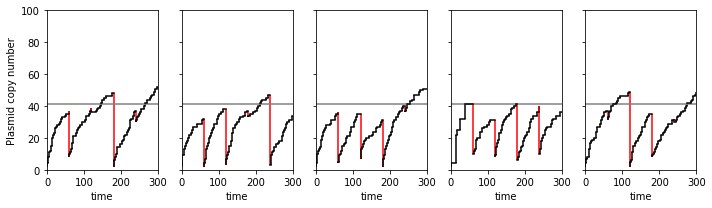

In [134]:
repeats = 5
gen=5
cluster=True
f,axes = plt.subplots(1,repeats,figsize=(10,3))
for i in range(repeats):
    x,t,_,__=single_lineage(x0,gen,tau,cluster,0)
    plot_stairs_multiple(x,t,i)
axes[0].set_ylabel('Plasmid copy number')    
plt.tight_layout()